# Задание 1
Проверяем утверждение: с ростом года выпуска фильма средний рейтинг становится ниже.

In [1]:
%pip install pandas

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.7 MB 9.1 MB/s eta 0:00:01
   ----------------- ---------------------- 4.2/9.7 MB 10.1 MB/s eta 0:00:01
   ---------------------------- ----------- 6.8/9.7 MB 10.0 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.7 MB 10.4 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 10.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------- -------------------------------- 2.4/12.6 MB 12.2 MB/s eta 0:00:01
   --------------- ------------------------ 5.0/12.6 MB 11.6 MB/s eta 0:00:01
   ----------------------- ---------------- 7.3/12.6 MB 11.6 MB/s eta 0:00:01
   ---------------------------- ----------- 8.9/12.6 MB 11.5 MB/s eta 0:00:01
   ------------------------------------ --- 11.5/12.6 MB 10.8 MB/s eta 0:00:01
   --------------


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

movies = pd.read_csv('movies_stats.csv')
movies.head()

,userId,movieId,rating,timestamp,title,genres
0,1,31,2.5,1260759144,Dangerous Minds (1995),Drama
1,1,1029,3.0,1260759179,Dumbo (1941),Animation|Children|Drama|Musical
2,1,1061,3.0,1260759182,Sleepers (1996),Thriller
3,1,1129,2.0,1260759185,Escape from New York (1981),Action|Adventure|Sci-Fi|Thriller
4,1,1172,4.0,1260759205,Cinema Paradiso (Nuovo cinema Paradiso) (1989),Drama


### 1. Список годов с 1950 по 2010

In [3]:
years = list(range(1950, 2011))
print(years[:3], '...', years[-3:], len(years))

[1950, 1951, 1952] ... [2008, 2009, 2010] 61


### 2. Функция `production_year`

In [4]:
def production_year(row):
    title = row['title']
    for year in years:
        if str(year) in title:
            return year
    return 1900

### 3. Новый столбец `year`

In [5]:
movies['year'] = movies.apply(production_year, axis=1)
movies[['title', 'year']].head(10)

,title,year
0,Dangerous Minds (1995),1995
1,Dumbo (1941),1900
2,Sleepers (1996),1996
3,Escape from New York (1981),1981
4,Cinema Paradiso (Nuovo cinema Paradiso) (1989),1989
5,"Deer Hunter, The (1978)",1978
6,Ben-Hur (1959),1959
7,Gandhi (1982),1982
8,Dracula (Bram Stoker's Dracula) (1992),1992
9,Cape Fear (1991),1991


### 4. Средний рейтинг по годам, по убыванию

In [6]:
year_rating = movies.groupby('year')['rating'].mean().sort_values(ascending=False)
year_rating

year
1957    4.014241
1972    4.011136
1952    4.000000
1954    3.994220
1951    3.983539
          ...   
2005    3.448434
2003    3.444777
1996    3.426600
1997    3.415764
2000    3.356104
Name: rating, Length: 62, dtype: float64

### Проверка утверждения
Посмотрим на корреляцию года и среднего рейтинга (без «заглушки» 1900).

Корреляция год ~ средний рейтинг: -0.823


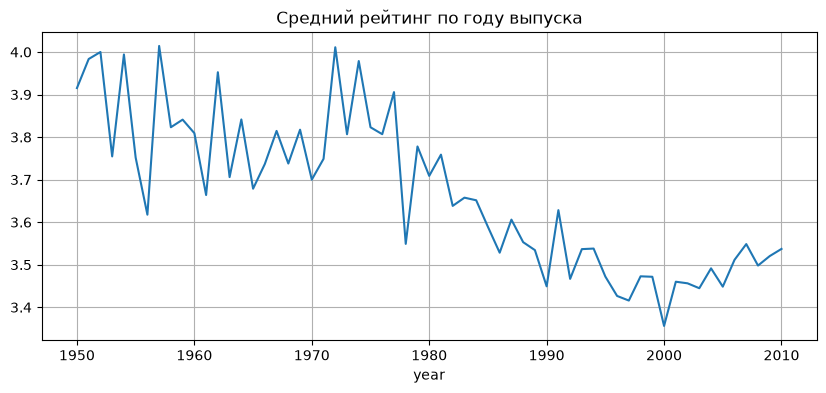

In [8]:
yr = year_rating.drop(1900, errors='ignore').sort_index()
print('Корреляция год ~ средний рейтинг:', round(yr.index.to_series().corr(yr), 3))
yr.plot(title='Средний рейтинг по году выпуска', figsize=(10, 4), grid=True);